In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
import os
import re
from pathlib import Path
import hashlib
from PIL import Image, ImageOps, ImageFile
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.applications.resnet50 import preprocess_input
import tensorflow as tf
from time import perf_counter
from datetime import datetime
from sklearn.metrics import classification_report, confusion_matrix

EPOCAS_MAXIMAS_FASE1 = 15
EPOCAS_PRUEBA = 2
IMAGENES_TRAIN_POR_CLASE = 128
IMAGENES_VAL_POR_CLASE = 32
TASA_APRENDIZAJE_INICIAL = 1e-3
DROPOUT_CLASIFICADOR = 0.30
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
CARPETA_PARTICIONES = Path("particiones")
train_visual = pd.read_csv(
    CARPETA_PARTICIONES / "imagenes_train.csv"
)
TASA_APRENDIZAJE_FASE2 = 1e-5
EPOCAS_MAXIMAS_FASE2 = 10
BLOQUE_A_AJUSTAR = "conv5_block3_"
TAMANO_ENTRADA = (320, 320)
SEMILLA = 42
OBJETIVO_POR_CLASE = 4000
CARPETA_REPORTES = Path("auditoria_piloto")
RUTA_INVENTARIO = Path(
    "auditoria_descarga/inventario_imagenes_disponibles.csv"
)

NOMBRES_CLASES = {0: "Poor", 1: "Fair", 2: "Good"}
NOMBRES_PARTICIONES = ["train", "val", "test"]

# 1. Exploración de data

In [5]:
# Ajusta estas rutas si el notebook está en otra carpeta.
RUTA_CSV = Path("data_support.csv")
RUTA_IMAGENES = Path("imagenes_nuevas")
SALIDA = Path("auditoria_descarga")

SALIDA.mkdir(exist_ok=True)

# Cargar el catálogo original.
original = pd.read_csv(RUTA_CSV)

if original["segmento_id"].duplicated().any():
    raise ValueError("El CSV original contiene segmentos repetidos.")

if not RUTA_IMAGENES.is_dir():
    raise FileNotFoundError(f"No existe la carpeta: {RUTA_IMAGENES.resolve()}")

# Reconocer nombres como 100_1.jpg, 100_2.png, etc.
patron = re.compile(r"^(\d+)_(\d+)$")
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

registros = []
nombres_no_reconocidos = []

# Recorrer todas las subcarpetas, sin asumir sus rangos de segmentos.
for carpeta, _, archivos in os.walk(RUTA_IMAGENES):
    for nombre in archivos:
        archivo = Path(nombre)

        if archivo.suffix.lower() not in extensiones:
            continue

        ruta = Path(carpeta) / nombre
        coincidencia = patron.fullmatch(archivo.stem)

        if coincidencia is None:
            nombres_no_reconocidos.append(str(ruta.resolve()))
            continue

        segmento_id = int(coincidencia.group(1))
        numero_imagen = int(coincidencia.group(2))

        registros.append(
            (segmento_id, numero_imagen, str(ruta.resolve()))
        )

inventario = pd.DataFrame(
    registros,
    columns=["segmento_id", "numero_imagen", "ruta"]
)

if inventario.empty:
    raise ValueError(
        "No se encontraron imágenes con el formato esperado. "
        "Revisa la ruta y los nombres."
    )

# Detectar imágenes con el mismo identificador, incluso entre carpetas.
claves = ["segmento_id", "numero_imagen"]

duplicados = inventario.loc[
    inventario.duplicated(claves, keep=False)
].copy()

segmentos_con_duplicados = set(duplicados["segmento_id"])

# Para los conteos, cada identificador de imagen se considera una sola vez.
catalogo_unico = inventario.drop_duplicates(claves)

# Identificar archivos cuyo segmento no aparece en el CSV original.
fuera_del_csv = inventario.loc[
    ~inventario["segmento_id"].isin(original["segmento_id"])
].copy()

print(f"Archivos con nombre reconocido: {len(inventario):,}")
print(f"Identificadores únicos de imagen: {len(catalogo_unico):,}")
print(f"Segmentos encontrados en disco: {inventario['segmento_id'].nunique():,}")
print(f"Archivos involucrados en duplicados: {len(duplicados):,}")
print(f"Archivos de segmentos ajenos al CSV: {len(fuera_del_csv):,}")
print(f"Imágenes con nombre no reconocido: {len(nombres_no_reconocidos):,}")

Archivos con nombre reconocido: 709,004
Identificadores únicos de imagen: 709,004
Segmentos encontrados en disco: 71,375
Archivos involucrados en duplicados: 0
Archivos de segmentos ajenos al CSV: 0
Imágenes con nombre no reconocido: 0


In [6]:
# Verificar que las cantidades esperadas sean enteros positivos.
cantidades = pd.to_numeric(
    original["cantidad_imagenes"],
    errors="raise"
)

if (
    cantidades.isna().any()
    or (cantidades <= 0).any()
    or (cantidades % 1 != 0).any()
):
    raise ValueError("Hay cantidades de imágenes vacías, no enteras o no positivas.")

original["cantidad_imagenes"] = cantidades.astype(int)

# Obtener los números de imagen encontrados para cada segmento.
indices_por_segmento = (
    catalogo_unico.groupby("segmento_id")["numero_imagen"]
    .agg(set)
    .to_dict()
)

resultados = []

for fila in original.itertuples(index=False):
    segmento = int(fila.segmento_id)

    esperados = set(range(1, fila.cantidad_imagenes + 1))
    encontrados = indices_por_segmento.get(segmento, set())

    faltantes = esperados - encontrados
    extras = encontrados - esperados
    coincidentes = esperados & encontrados

    tiene_duplicados = segmento in segmentos_con_duplicados

    # Clasificar la situación de cada segmento.
    if not encontrados:
        estado = "sin_archivos"
    elif faltantes:
        estado = "incompleto"
    elif extras or tiene_duplicados:
        estado = "revisar"
    else:
        estado = "completo"

    resultados.append({
        "segmento_id": segmento,
        "imagenes_en_disco": len(encontrados),
        "imagenes_esperadas_presentes": len(coincidentes),
        "cantidad_faltantes": len(faltantes),
        "indices_faltantes": ";".join(map(str, sorted(faltantes))),
        "indices_extra": ";".join(map(str, sorted(extras))),
        "tiene_duplicados": tiene_duplicados,
        "estado": estado
    })

# Unir los resultados con las etiquetas originales.
auditoria = original.merge(
    pd.DataFrame(resultados),
    on="segmento_id",
    how="left",
    validate="one_to_one"
)

# Resumen general.
resumen_auditoria = (
    auditoria.groupby("estado")
    .agg(
        segmentos=("segmento_id", "count"),
        imagenes_previstas=("cantidad_imagenes", "sum"),
        imagenes_esperadas_presentes=("imagenes_esperadas_presentes", "sum"),
        imagenes_faltantes=("cantidad_faltantes", "sum")
    )
)

display(resumen_auditoria)

print(f"Segmentos del CSV original: {len(original):,}")
print(f"Imágenes previstas en el CSV: {original['cantidad_imagenes'].sum():,}")
print(
    f"Imágenes esperadas encontradas: "
    f"{auditoria['imagenes_esperadas_presentes'].sum():,}"
)
print(
    f"Imágenes esperadas faltantes: "
    f"{auditoria['cantidad_faltantes'].sum():,}"
)

# Mostrar las pérdidas por clase.
print("\n=== DISPONIBILIDAD POR CLASE Y ESTADO ===")

display(
    auditoria.assign(
        clase=auditoria["clase_original"].map(
            {0: "Poor", 1: "Fair", 2: "Good"}
        )
    )
    .groupby(["clase", "estado"])
    .agg(
        segmentos=("segmento_id", "count"),
        imagenes_previstas=("cantidad_imagenes", "sum"),
        imagenes_faltantes=("cantidad_faltantes", "sum")
    )
)

,segmentos,imagenes_previstas,imagenes_esperadas_presentes,imagenes_faltantes
estado,,,,
completo,71375,709004,709004,0
sin_archivos,226,2516,0,2516


Segmentos del CSV original: 71,601
Imágenes previstas en el CSV: 711,520
Imágenes esperadas encontradas: 709,004
Imágenes esperadas faltantes: 2,516

=== DISPONIBILIDAD POR CLASE Y ESTADO ===


segmentos  imagenes_previstas  imagenes_faltantes
clase estado                                                         
Fair  completo          20564              199977                   0
      sin_archivos         48                 576                 576
Good  completo          50293              504377                   0
      sin_archivos        178                1940                1940
Poor  completo            518                4650                   0

In [7]:
# Segmentos con al menos una imagen esperada presente.
presentes = auditoria.loc[
    auditoria["imagenes_esperadas_presentes"] > 0
].copy()

# Catálogo conservador: solo segmentos completos y sin anomalías.
# Mantener las columnas originales para reutilizar las celdas del notebook.
disponibles = auditoria.loc[
    auditoria["estado"] == "completo",
    original.columns
].copy()

# Inventario de rutas reales correspondiente al catálogo utilizable.
inventario_disponibles = inventario.loc[
    inventario["segmento_id"].isin(disponibles["segmento_id"])
].sort_values(["segmento_id", "numero_imagen"])

# Guardar resultados principales.
auditoria.to_csv(
    SALIDA / "auditoria_segmentos.csv",
    index=False,
    encoding="utf-8-sig"
)

presentes.to_csv(
    SALIDA / "segmentos_presentes.csv",
    index=False,
    encoding="utf-8-sig"
)

disponibles.to_csv(
    SALIDA / "segmentos_disponibles.csv",
    index=False,
    encoding="utf-8-sig"
)

inventario_disponibles.to_csv(
    SALIDA / "inventario_imagenes_disponibles.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar también los casos que requieren revisión.
duplicados.to_csv(
    SALIDA / "archivos_duplicados.csv",
    index=False,
    encoding="utf-8-sig"
)

fuera_del_csv.to_csv(
    SALIDA / "imagenes_fuera_del_csv.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(
    nombres_no_reconocidos,
    columns=["ruta"]
).to_csv(
    SALIDA / "nombres_no_reconocidos.csv",
    index=False,
    encoding="utf-8-sig"
)

print(f"Resultados guardados en: {SALIDA.resolve()}")
print(f"Segmentos completos utilizables: {len(disponibles):,}")
print(
    f"Imágenes en segmentos completos: "
    f"{disponibles['cantidad_imagenes'].sum():,}"
)

Resultados guardados en: C:\Users\Diego\Desktop\Tesis_Pavimento\auditoria_descarga
Segmentos completos utilizables: 71,375
Imágenes en segmentos completos: 709,004


In [8]:
# Cargar el CSV con sus encabezados.
df = pd.read_csv("auditoria_descarga/segmentos_disponibles.csv")

# Cada segmento debe aparecer una sola vez.
if df["segmento_id"].duplicated().any():
    raise ValueError("Hay segmentos duplicados. Revísalos antes de contar.")

# Correspondencia de las etiquetas del dataset.
clases = {0: "Poor", 1: "Fair", 2: "Good"}

if not df["clase_original"].isin(clases).all():
    raise ValueError("Hay clases vacías o diferentes de 0, 1 y 2.")

# Contar segmentos y sumar las imágenes de cada clase.
resumen = (
    df.groupby("clase_original")
    .agg(
        segmentos=("segmento_id", "count"),
        imagenes=("cantidad_imagenes", "sum")
    )
    .reindex([0, 1, 2], fill_value=0)
    .rename(index=clases)
)

resumen.index.name = "Clase"

display(resumen)

# Cantidad total de imágenes indicada en el CSV.
print(f"Total de imágenes: {df['cantidad_imagenes'].sum():,}")

,segmentos,imagenes
Clase,,
Poor,518,4650
Fair,20564,199977
Good,50293,504377


Total de imágenes: 709,004


In [9]:
# Función para calcular la clase esperada
def calcular_clase_esperada(puntuacion):
  if 1 <= puntuacion <= 3:
    return 0  # Poor
  elif 4 <= puntuacion <= 7:
    return 1  # Fair
  elif 8 <= puntuacion <= 10:
    return 2  # Good
  else:
    return None


# Crear columnas de control
df['clase_esperada'] = df['puntuacion_original'].apply(calcular_clase_esperada)

if df['clase_esperada'].isna().any():
  raise ValueError('Hay puntuaciones vacías o fuera de los rangos definidos.')

df['hay_discrepancia'] = df['clase_original'] != df['clase_esperada']

# Crear una tabla cruzada (Matriz de confusión) para ver el cruce real vs esperado
# Solo tomamos las filas con discrepancia para enfocar el análisis
discrepancias = df.loc[df['hay_discrepancia']].copy()

# Generar la tabla cruzada de conteo de segmentos
tabla_cruzada_segmentos = pd.crosstab(
    df['clase_original'].map(NOMBRES_CLASES),
    df['clase_esperada'].map(NOMBRES_CLASES),
    margins=True,  # Agrega totales por filas y columnas
    margins_name='Total',
)

print('=== MATRIZ DE DISCREPANCIAS (Cantidad de Segmentos) ===')
display(tabla_cruzada_segmentos)

# Ver el total de imágenes afectadas en este cruce
tabla_cruzada_imagenes = pd.crosstab(
    df['clase_original'].map(NOMBRES_CLASES),
    df['clase_esperada'].map(NOMBRES_CLASES),
    values=df['cantidad_imagenes'],
    aggfunc='sum',
    margins=True,
    margins_name='Total',
).fillna(0)

print('\n=== MATRIZ DE DISCREPANCIAS (Suma de Imágenes) ===')
display(tabla_cruzada_imagenes)

# Sumar las imágenes asociadas a los segmentos con discrepancia
total_imagenes_discrepancia = discrepancias['cantidad_imagenes'].sum()
print(f'\nTotal general de imágenes con discrepancia: {total_imagenes_discrepancia:,}')

=== MATRIZ DE DISCREPANCIAS (Cantidad de Segmentos) ===


clase_esperada,Fair,Good,Poor,Total
clase_original,,,,
Fair,20564,0,0,20564
Good,9734,40559,0,50293
Poor,0,0,518,518
Total,30298,40559,518,71375



=== MATRIZ DE DISCREPANCIAS (Suma de Imágenes) ===


clase_esperada,Fair,Good,Poor,Total
clase_original,,,,
Fair,199977.0,0.0,0.0,199977
Good,106854.0,397523.0,0.0,504377
Poor,0.0,0.0,4650.0,4650
Total,306831.0,397523.0,4650.0,709004



Total general de imágenes con discrepancia: 106,854


# 2. Selección del subconjunto piloto

Se seleccionará un piloto de aproximadamente **12 000 imágenes**, con unas **4000 por clase**: Poor, Fair y Good.

La selección será aleatoria, utilizando segmentos completos y una semilla fija de **42** para poder repetirla. Se conservarán las etiquetas originales y, dentro de Good, se mantendrá aproximadamente la proporción de imágenes con discrepancia.

Las cantidades podrán variar ligeramente porque cada segmento contiene un número diferente de imágenes. Estos conteos corresponden a lo registrado en el ground truth.

In [10]:
# Configuración del piloto.
def seleccionar_segmentos(candidatos, objetivo):
    # Permitir un objetivo de cero si algún grupo no tiene discrepancias.
    if objetivo == 0:
        return candidatos.iloc[:0].copy()

    disponibles = candidatos["cantidad_imagenes"].sum()

    if disponibles < objetivo:
        raise ValueError(
            f"El grupo tiene {disponibles} imágenes, "
            f"pero el objetivo es {objetivo}."
        )

    # Ordenar primero permite repetir la selección aunque cambie el orden del CSV.
    aleatorios = (
        candidatos.sort_values("segmento_id")
        .sample(frac=1, random_state=SEMILLA)
        .reset_index(drop=True)
    )

    # Sumar las imágenes conforme se incorporan segmentos completos.
    acumulado = aleatorios["cantidad_imagenes"].cumsum()

    # Encontrar el punto cuya suma queda más cerca del objetivo.
    posicion = (acumulado - objetivo).abs().idxmin()

    return aleatorios.iloc[:posicion + 1].copy()


# Seleccionar Poor y Fair según sus etiquetas originales.
piloto_poor = seleccionar_segmentos(
    df.loc[df["clase_original"] == 0],
    OBJETIVO_POR_CLASE
)

piloto_fair = seleccionar_segmentos(
    df.loc[df["clase_original"] == 1],
    OBJETIVO_POR_CLASE
)

In [11]:
# Separar Good en dos grupos conservando su etiqueta original.
good = df.loc[df["clase_original"] == 2].copy()

good_con_discrepancia = good.loc[good["hay_discrepancia"]]
good_sin_discrepancia = good.loc[~good["hay_discrepancia"]]

# Calcular la proporción por número de imágenes.
total_imagenes_good = good["cantidad_imagenes"].sum()

proporcion_discrepancia_good = (
    good_con_discrepancia["cantidad_imagenes"].sum()
    / total_imagenes_good
)

# Distribuir las 4000 imágenes objetivo respetando esa proporción.
objetivo_good_con = round(
    OBJETIVO_POR_CLASE * proporcion_discrepancia_good
)

objetivo_good_sin = OBJETIVO_POR_CLASE - objetivo_good_con

print(
    f"Proporción original de discrepancias en Good: "
    f"{proporcion_discrepancia_good:.2%}"
)
print(f"Objetivo Good con discrepancia: {objetivo_good_con}")
print(f"Objetivo Good sin discrepancia: {objetivo_good_sin}")

# Seleccionar segmentos completos de ambos grupos.
piloto_good_con = seleccionar_segmentos(
    good_con_discrepancia,
    objetivo_good_con
)

piloto_good_sin = seleccionar_segmentos(
    good_sin_discrepancia,
    objetivo_good_sin
)

Proporción original de discrepancias en Good: 21.19%
Objetivo Good con discrepancia: 847
Objetivo Good sin discrepancia: 3153


In [12]:
# Reunir los cuatro grupos seleccionados.
piloto = (
    pd.concat(
        [
            piloto_poor,
            piloto_fair,
            piloto_good_sin,
            piloto_good_con
        ],
        ignore_index=True
    )
    .sort_values("segmento_id")
    .reset_index(drop=True)
)

# Comprobar que cada segmento aparezca una sola vez.
if piloto["segmento_id"].duplicated().any():
    raise ValueError("Hay segmentos repetidos en la selección.")

# Contar las imágenes asociadas a segmentos con discrepancia.
piloto["imagenes_con_discrepancia"] = (
    piloto["cantidad_imagenes"]
    .where(piloto["hay_discrepancia"], 0)
)

# Resumen de los resultados por clase original.
resumen_piloto = (
    piloto.groupby("clase_original")
    .agg(
        segmentos=("segmento_id", "count"),
        imagenes=("cantidad_imagenes", "sum"),
        segmentos_con_discrepancia=("hay_discrepancia", "sum"),
        imagenes_con_discrepancia=("imagenes_con_discrepancia", "sum")
    )
    .reindex([0, 1, 2], fill_value=0)
    .rename(index=NOMBRES_CLASES)
)

resumen_piloto.index.name = "Clase"

display(resumen_piloto)

print(f"Total de segmentos seleccionados: {len(piloto):,}")
print(f"Total de imágenes previstas: {piloto['cantidad_imagenes'].sum():,}")
print(
    f"Total de imágenes con discrepancia: "
    f"{piloto['imagenes_con_discrepancia'].sum():,}"
)

# Comparar la proporción de discrepancias en Good.
proporcion_good_piloto = (
    resumen_piloto.loc["Good", "imagenes_con_discrepancia"]
    / resumen_piloto.loc["Good", "imagenes"]
)

print(
    f"\nDiscrepancias dentro de Good — dataset original: "
    f"{proporcion_discrepancia_good:.2%}"
)
print(
    f"Discrepancias dentro de Good — piloto: "
    f"{proporcion_good_piloto:.2%}"
)

# Registrar la semilla utilizada.
piloto["semilla_seleccion"] = SEMILLA

# Guardar la selección y su resumen.
piloto.to_csv(
    "segmentos_piloto.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_piloto.to_csv(
    "resumen_piloto.csv",
    encoding="utf-8-sig"
)

print("\nArchivos guardados:")
print("- segmentos_piloto.csv")
print("- resumen_piloto.csv")

,segmentos,imagenes,segmentos_con_discrepancia,imagenes_con_discrepancia
Clase,,,,
Poor,445,4001,0,0
Fair,419,4012,0,0
Good,402,3999,74,844


Total de segmentos seleccionados: 1,266
Total de imágenes previstas: 12,012
Total de imágenes con discrepancia: 844

Discrepancias dentro de Good — dataset original: 21.19%
Discrepancias dentro de Good — piloto: 21.11%

Archivos guardados:
- segmentos_piloto.csv
- resumen_piloto.csv


# 3. Particionamiento de datos

In [13]:
# Trabajar sobre una copia ordenada para obtener resultados reproducibles.
base = piloto.copy().sort_values("segmento_id").reset_index(drop=True)

# Cada fila debe representar un segmento diferente.
if base["segmento_id"].duplicated().any():
    raise ValueError("Hay segmentos duplicados en el piloto.")

# Crear grupos de estratificación por clase y presencia de discrepancia.
# Esto permite repartir también los dos subgrupos de Good.
base["estrato"] = (
    base["clase_original"].astype(str)
    + "_"
    + base["hay_discrepancia"].astype(int).astype(str)
)

# 1. Separar 70 % para entrenamiento y 30 % temporal.
train_segmentos, temporal = train_test_split(
    base,
    test_size=0.30,
    random_state=SEMILLA,
    stratify=base["estrato"]
)

# 2. Dividir el 30 % temporal en dos mitades: validación y prueba.
val_segmentos, test_segmentos = train_test_split(
    temporal,
    test_size=0.50,
    random_state=SEMILLA + 1,
    stratify=temporal["estrato"]
)

# Identificar la partición de cada segmento y retirar la columna auxiliar.
particiones = {
    "train": train_segmentos,
    "val": val_segmentos,
    "test": test_segmentos
}

for nombre, datos in particiones.items():
    datos = (
        datos.drop(columns="estrato")
        .sort_values("segmento_id")
        .reset_index(drop=True)
    )

    datos["particion"] = nombre
    particiones[nombre] = datos

# Reunir las particiones para comprobar y resumir la división.
piloto_dividido = pd.concat(particiones.values(), ignore_index=True)

# Verificar que todos los segmentos aparezcan exactamente una vez.
if (
    piloto_dividido["segmento_id"].duplicated().any()
    or set(piloto_dividido["segmento_id"]) != set(base["segmento_id"])
):
    raise ValueError("La división contiene segmentos repetidos o faltantes.")

# Contar las imágenes asociadas a segmentos con discrepancia.
piloto_dividido["imagenes_con_discrepancia"] = (
    piloto_dividido["cantidad_imagenes"]
    .where(piloto_dividido["hay_discrepancia"], 0)
)

# Resumen general de cada partición.
orden = ["train", "val", "test"]

resumen_division = (
    piloto_dividido.groupby("particion")
    .agg(
        segmentos=("segmento_id", "count"),
        imagenes=("cantidad_imagenes", "sum"),
        segmentos_con_discrepancia=("hay_discrepancia", "sum"),
        imagenes_con_discrepancia=("imagenes_con_discrepancia", "sum")
    )
    .reindex(orden)
)

resumen_division["porcentaje_segmentos"] = (
    resumen_division["segmentos"] / len(base) * 100
)

resumen_division["porcentaje_imagenes"] = (
    resumen_division["imagenes"] / base["cantidad_imagenes"].sum() * 100
)

print("=== RESUMEN DE LA DIVISIÓN ===")
display(resumen_division.round(2))

# Mostrar segmentos e imágenes por clase dentro de cada partición.
detalle_clases = (
    piloto_dividido.assign(
        clase=piloto_dividido["clase_original"].map(
            {0: "Poor", 1: "Fair", 2: "Good"}
        )
    )
    .groupby(["particion", "clase"])
    .agg(
        segmentos=("segmento_id", "count"),
        imagenes=("cantidad_imagenes", "sum"),
        imagenes_con_discrepancia=("imagenes_con_discrepancia", "sum")
    )
    .reindex(
        pd.MultiIndex.from_product(
            [orden, ["Poor", "Fair", "Good"]],
            names=["particion", "clase"]
        ),
        fill_value=0
    )
)

CARPETA_PARTICIONES.mkdir(exist_ok=True)

print("\n=== DISTRIBUCIÓN POR CLASE ===")
display(detalle_clases)

# Guardar un archivo por partición.
for nombre, datos in particiones.items():
    datos.to_csv(
        CARPETA_PARTICIONES / f"segmentos_{nombre}.csv",
        index=False,
        encoding="utf-8-sig"
    )

# Guardar también el registro completo de la división.
piloto_dividido.to_csv(
    CARPETA_PARTICIONES / "segmentos_piloto_divididos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nVerificación correcta: todos los segmentos están en una sola partición.")
print(f"Total de segmentos: {len(piloto_dividido):,}")
print(f"Total de imágenes previstas: {piloto_dividido['cantidad_imagenes'].sum():,}")

print("\nArchivos guardados:")
print("- segmentos_train.csv")
print("- segmentos_val.csv")
print("- segmentos_test.csv")
print("- segmentos_piloto_divididos.csv")

=== RESUMEN DE LA DIVISIÓN ===


,segmentos,imagenes,segmentos_con_discrepancia,imagenes_con_discrepancia,porcentaje_segmentos,porcentaje_imagenes
particion,,,,,,
train,886,8404,52,573,69.98,69.96
val,190,1877,11,142,15.01,15.63
test,190,1731,11,129,15.01,14.41



=== DISTRIBUCIÓN POR CLASE ===


segmentos  imagenes  imagenes_con_discrepancia
particion clase                                                
train     Poor         311      2822                          0
          Fair         293      2813                          0
          Good         282      2769                        573
val       Poor          67       585                          0
          Fair          63       678                          0
          Good          60       614                        142
test      Poor          67       594                          0
          Fair          63       521                          0
          Good          60       616                        129


Verificación correcta: todos los segmentos están en una sola partición.
Total de segmentos: 1,266
Total de imágenes previstas: 12,012

Archivos guardados:
- segmentos_train.csv
- segmentos_val.csv
- segmentos_test.csv
- segmentos_piloto_divididos.csv


In [14]:
# Rutas de los archivos creados anteriormente.
columnas_segmentos = [
    "segmento_id",
    "cantidad_imagenes",
    "clase_original",
    "hay_discrepancia",
]

# 1. Cargar las particiones existentes.
tablas_segmentos = []

for nombre in NOMBRES_PARTICIONES:
    ruta_csv = CARPETA_PARTICIONES / f"segmentos_{nombre}.csv"

    tabla = pd.read_csv(
        ruta_csv,
        dtype={
            "segmento_id": "int64",
            "cantidad_imagenes": "int64",
            "clase_original": "int64",
        },
    )

    faltan = set(columnas_segmentos) - set(tabla.columns)
    if faltan:
        raise ValueError(f"Faltan columnas en {ruta_csv.name}: {faltan}")

    if tabla.empty:
        raise ValueError(f"La partición {nombre} está vacía.")

    # Comprobar que la partición guardada coincide con el archivo.
    if "particion" in tabla.columns:
        if not tabla["particion"].eq(nombre).all():
            raise ValueError(f"Partición incorrecta en {ruta_csv.name}")

    tabla = tabla[columnas_segmentos].copy()
    tabla["particion"] = nombre
    tablas_segmentos.append(tabla)

segmentos = pd.concat(tablas_segmentos, ignore_index=True)

# Cada segmento debe pertenecer a una sola partición.
if segmentos["segmento_id"].duplicated().any():
    raise ValueError("Hay segmentos repetidos dentro de las particiones o entre ellas.")

if segmentos[columnas_segmentos].isna().any().any():
    raise ValueError("Hay datos vacíos en los registros de segmentos.")

if not segmentos["clase_original"].isin(NOMBRES_CLASES).all():
    raise ValueError("Hay clases diferentes de 0, 1 y 2.")

if segmentos["cantidad_imagenes"].le(0).any():
    raise ValueError("Hay segmentos con una cantidad de imágenes no válida.")

# 2. Cargar el inventario de rutas reales.
inventario = pd.read_csv(
    RUTA_INVENTARIO,
    usecols=["segmento_id", "numero_imagen", "ruta"],
    dtype={
        "segmento_id": "int64",
        "numero_imagen": "int64",
        "ruta": "string",
    },
)

# Conservar únicamente las imágenes de los segmentos del piloto.
inventario_piloto = inventario.loc[
    inventario["segmento_id"].isin(segmentos["segmento_id"])
].copy()

if (
    inventario_piloto["ruta"].isna().any()
    or inventario_piloto["ruta"].str.strip().eq("").any()
):
    raise ValueError("Hay rutas vacías en el inventario del piloto.")

if inventario_piloto.duplicated(["segmento_id", "numero_imagen"]).any():
    raise ValueError("Hay identificadores de imagen repetidos en el piloto.")

if inventario_piloto["ruta"].duplicated().any():
    raise ValueError("La misma ruta aparece asignada más de una vez.")

# 3. Comprobar la cantidad de imágenes de CADA segmento.
conteos = inventario_piloto.groupby("segmento_id").size()

comprobacion = segmentos[
    ["segmento_id", "particion", "cantidad_imagenes"]
].copy()

comprobacion["imagenes_en_inventario"] = (
    comprobacion["segmento_id"].map(conteos).fillna(0).astype(int)
)

errores = comprobacion.loc[
    comprobacion["cantidad_imagenes"]
    != comprobacion["imagenes_en_inventario"]
]

if not errores.empty:
    display(errores)
    raise ValueError(
        "Las cantidades no coinciden. Revisa los segmentos mostrados "
        "antes de generar los CSV."
    )

# 4. Asociar cada imagen con la etiqueta y partición de su segmento.
imagenes = inventario_piloto.merge(
    segmentos,
    on="segmento_id",
    how="left",
    validate="many_to_one",
)

# El inventario anterior utiliza números de imagen desde 1 hasta N.
indices_validos = (
    imagenes["numero_imagen"].ge(1)
    & imagenes["numero_imagen"].le(imagenes["cantidad_imagenes"])
)

if not indices_validos.all():
    raise ValueError("Hay números de imagen fuera del rango esperado.")

imagenes["clase"] = imagenes["clase_original"].map(NOMBRES_CLASES)

columnas_salida = [
    "ruta",
    "segmento_id",
    "numero_imagen",
    "clase_original",
    "clase",
    "hay_discrepancia",
    "particion",
]

# 5. Guardar los tres CSV después de superar las comprobaciones.
for nombre in NOMBRES_PARTICIONES:
    tabla_imagenes = (
        imagenes.loc[imagenes["particion"].eq(nombre), columnas_salida]
        .sort_values(["segmento_id", "numero_imagen"])
        .reset_index(drop=True)
    )

    ruta_salida = CARPETA_PARTICIONES / f"imagenes_{nombre}.csv"
    tabla_imagenes.to_csv(ruta_salida, index=False, encoding="utf-8-sig")

    print(f"Guardado: {ruta_salida} — {len(tabla_imagenes):,} imágenes")

# 6. Mostrar el resumen final.
resumen = (
    imagenes.groupby("particion")
    .agg(
        segmentos=("segmento_id", "nunique"),
        imagenes=("ruta", "size"),
    )
    .reindex(NOMBRES_PARTICIONES)
)

print("\n=== RESUMEN DE LOS REGISTROS POR IMAGEN ===")
display(resumen)

print("\n=== IMÁGENES POR CLASE Y PARTICIÓN ===")
distribucion = pd.crosstab(
    imagenes["particion"],
    imagenes["clase"],
).reindex(
    index=NOMBRES_PARTICIONES,
    columns=["Poor", "Fair", "Good"],
    fill_value=0,
)
display(distribucion)

print(f"\nTotal de imágenes registradas: {len(imagenes):,}")

Guardado: particiones\imagenes_train.csv — 8,404 imágenes
Guardado: particiones\imagenes_val.csv — 1,877 imágenes
Guardado: particiones\imagenes_test.csv — 1,731 imágenes

=== RESUMEN DE LOS REGISTROS POR IMAGEN ===


,segmentos,imagenes
particion,,
train,886,8404
val,190,1877
test,190,1731



=== IMÁGENES POR CLASE Y PARTICIÓN ===


clase,Poor,Fair,Good
particion,,,
train,2822,2813,2769
val,585,678,614
test,594,521,616



Total de imágenes registradas: 12,012


In [15]:
CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)

# Evitar que Pillow acepte imágenes truncadas silenciosamente.
ImageFile.LOAD_TRUNCATED_IMAGES = False

# 1. Cargar los registros por imagen.
tablas = []

for particion in NOMBRES_PARTICIONES:
    ruta_csv = CARPETA_PARTICIONES / f"imagenes_{particion}.csv"
    tabla = pd.read_csv(ruta_csv)

    if tabla.empty:
        raise ValueError(f"El archivo {ruta_csv.name} está vacío.")

    if not tabla["particion"].eq(particion).all():
        raise ValueError(f"Hay particiones incorrectas en {ruta_csv.name}.")

    tablas.append(tabla)

registros = pd.concat(tablas, ignore_index=True)

columnas_obligatorias = [
    "ruta", "segmento_id", "numero_imagen", "clase_original", "particion"
]

if registros[columnas_obligatorias].isna().any().any():
    raise ValueError("Hay datos vacíos en los registros.")

if registros["ruta"].astype(str).str.strip().eq("").any():
    raise ValueError("Hay rutas vacías.")

if registros.duplicated(["segmento_id", "numero_imagen"]).any():
    raise ValueError("Una misma imagen está registrada más de una vez.")

if registros.groupby("segmento_id")["particion"].nunique().gt(1).any():
    raise ValueError("Un segmento aparece en más de una partición.")


# 2. Definir la revisión de cada archivo.
def revisar_imagen(ruta):
    resultado = {
        "estado": "ok",
        "detalle": "",
        "ancho": None,
        "alto": None,
        "modo": None,
        "canales": None,
        "formato": None,
        "orientacion_exif": None,
        "hash_rgb": None,
    }

    try:
        # Revisar la estructura del archivo.
        with Image.open(ruta) as img:
            img.verify()

        # Reabrir: verify() invalida el objeto anterior.
        with Image.open(ruta) as img:
            resultado.update({
                "ancho": img.width,
                "alto": img.height,
                "modo": img.mode,
                "canales": len(img.getbands()),
                "formato": img.format,
                "orientacion_exif": img.getexif().get(274, 1),
            })

            # Este piloto está pensado para imágenes estáticas.
            if getattr(img, "n_frames", 1) != 1:
                resultado["estado"] = "requiere_revision"
                resultado["detalle"] = "Archivo con varios fotogramas."
                return resultado

            # Forzar la decodificación completa.
            img.load()

            # Normalizar orientación y color SOLO en memoria.
            # No se modifica el archivo original ni se redimensiona.
            orientada = ImageOps.exif_transpose(img)

            with orientada.convert("RGB") as rgb:
                huella = hashlib.sha256()

                # Incluir dimensiones para comparar tamaño y píxeles.
                huella.update(
                    f"RGB|{rgb.width}|{rgb.height}|".encode("utf-8")
                )
                huella.update(rgb.tobytes())

                resultado["hash_rgb"] = huella.hexdigest()

            orientada.close()

    except FileNotFoundError:
        resultado["estado"] = "faltante"
        resultado["detalle"] = "No se encontró el archivo en la ruta indicada."

    except Exception as error:
        resultado["estado"] = "error_lectura"
        resultado["detalle"] = f"{type(error).__name__}: {error}"

    return resultado


# 3. Revisar todas las imágenes del piloto.
resultados = []

for ruta in tqdm(
    registros["ruta"],
    total=len(registros),
    desc="Verificando imágenes",
    unit="imagen",
):
    resultados.append(revisar_imagen(ruta))

auditoria = pd.concat(
    [registros, pd.DataFrame(resultados)],
    axis=1,
)

# Usar enteros que admiten valores vacíos para archivos no legibles.
for columna in ["ancho", "alto", "canales", "orientacion_exif"]:
    auditoria[columna] = auditoria[columna].astype("Int64")

incidencias = auditoria.loc[auditoria["estado"].ne("ok")].copy()
legibles = auditoria.loc[auditoria["estado"].eq("ok")].copy()


# 4. Buscar imágenes con los mismos píxeles RGB y dimensiones.
# Se incluyen TODAS las imágenes de cada grupo repetido.
duplicados = legibles.loc[
    legibles["hash_rgb"].duplicated(keep=False)
].copy()

grupos = duplicados.groupby("hash_rgb")

duplicados["cantidad_en_grupo"] = grupos["ruta"].transform("size")
duplicados["entre_particiones"] = (
    grupos["particion"].transform("nunique").gt(1)
)
duplicados["clases_distintas"] = (
    grupos["clase_original"].transform("nunique").gt(1)
)

duplicados = duplicados.sort_values(
    ["hash_rgb", "particion", "segmento_id", "numero_imagen"]
)

duplicados_entre_particiones = duplicados.loc[
    duplicados["entre_particiones"]
].copy()


# 5. Guardar reportes sin modificar los CSV del entrenamiento.
reportes = {
    "auditoria_imagenes.csv": auditoria,
    "incidencias_imagenes.csv": incidencias,
    "duplicados_contenido.csv": duplicados,
    "duplicados_entre_particiones.csv": duplicados_entre_particiones,
}

for nombre, tabla in reportes.items():
    tabla.to_csv(
        CARPETA_REPORTES / nombre,
        index=False,
        encoding="utf-8-sig",
    )


# 6. Mostrar resultados.
print("\n=== ESTADO DE LAS IMÁGENES POR PARTICIÓN ===")

resumen_estados = pd.crosstab(
    auditoria["particion"],
    auditoria["estado"],
).reindex(
    index=NOMBRES_PARTICIONES,
    columns=["ok", "faltante", "error_lectura", "requiere_revision"],
    fill_value=0,
)

display(resumen_estados)

print("\n=== DIMENSIONES, COLOR Y FORMATO DE LAS IMÁGENES LEGIBLES ===")

resumen_formatos = (
    legibles.groupby(
        ["ancho", "alto", "modo", "canales", "formato"],
        dropna=False,
    )
    .size()
    .reset_index(name="imagenes")
    .sort_values("imagenes", ascending=False)
)

display(resumen_formatos)

print("\n=== RESUMEN GENERAL ===")
print(f"Imágenes registradas: {len(auditoria):,}")
print(f"Imágenes legibles: {len(legibles):,}")
print(f"Imágenes con incidencias: {len(incidencias):,}")

print(
    f"\nGrupos de contenido repetido: "
    f"{duplicados['hash_rgb'].nunique():,}"
)
print(f"Imágenes pertenecientes a esos grupos: {len(duplicados):,}")

print(
    f"Grupos repetidos entre particiones: "
    f"{duplicados_entre_particiones['hash_rgb'].nunique():,}"
)
print(
    f"Grupos repetidos con clases diferentes: "
    f"{duplicados.loc[duplicados['clases_distintas'], 'hash_rgb'].nunique():,}"
)

if not incidencias.empty:
    print("\nPrimeras incidencias:")
    display(
        incidencias[
            ["ruta", "particion", "estado", "detalle"]
        ].head(10)
    )

if not duplicados.empty:
    print("\nPrimeros registros con contenido repetido:")
    display(
        duplicados[
            [
                "ruta",
                "segmento_id",
                "clase",
                "particion",
                "cantidad_en_grupo",
                "entre_particiones",
                "clases_distintas",
            ]
        ].head(20)
    )

print("\nReportes guardados en:", CARPETA_REPORTES.resolve())

Verificando imágenes:   0%|          | 0/12012 [00:00<?, ?imagen/s]


=== ESTADO DE LAS IMÁGENES POR PARTICIÓN ===


estado,ok,faltante,error_lectura,requiere_revision
particion,,,,
train,8404,0,0,0
val,1877,0,0,0
test,1731,0,0,0



=== DIMENSIONES, COLOR Y FORMATO DE LAS IMÁGENES LEGIBLES ===


,ancho,alto,modo,canales,formato,imagenes
0,640,640,RGB,3,JPEG,12012



=== RESUMEN GENERAL ===
Imágenes registradas: 12,012
Imágenes legibles: 12,012
Imágenes con incidencias: 0

Grupos de contenido repetido: 0
Imágenes pertenecientes a esos grupos: 0
Grupos repetidos entre particiones: 0
Grupos repetidos con clases diferentes: 0

Reportes guardados en: C:\Users\Diego\Desktop\Tesis_Pavimento\auditoria_piloto


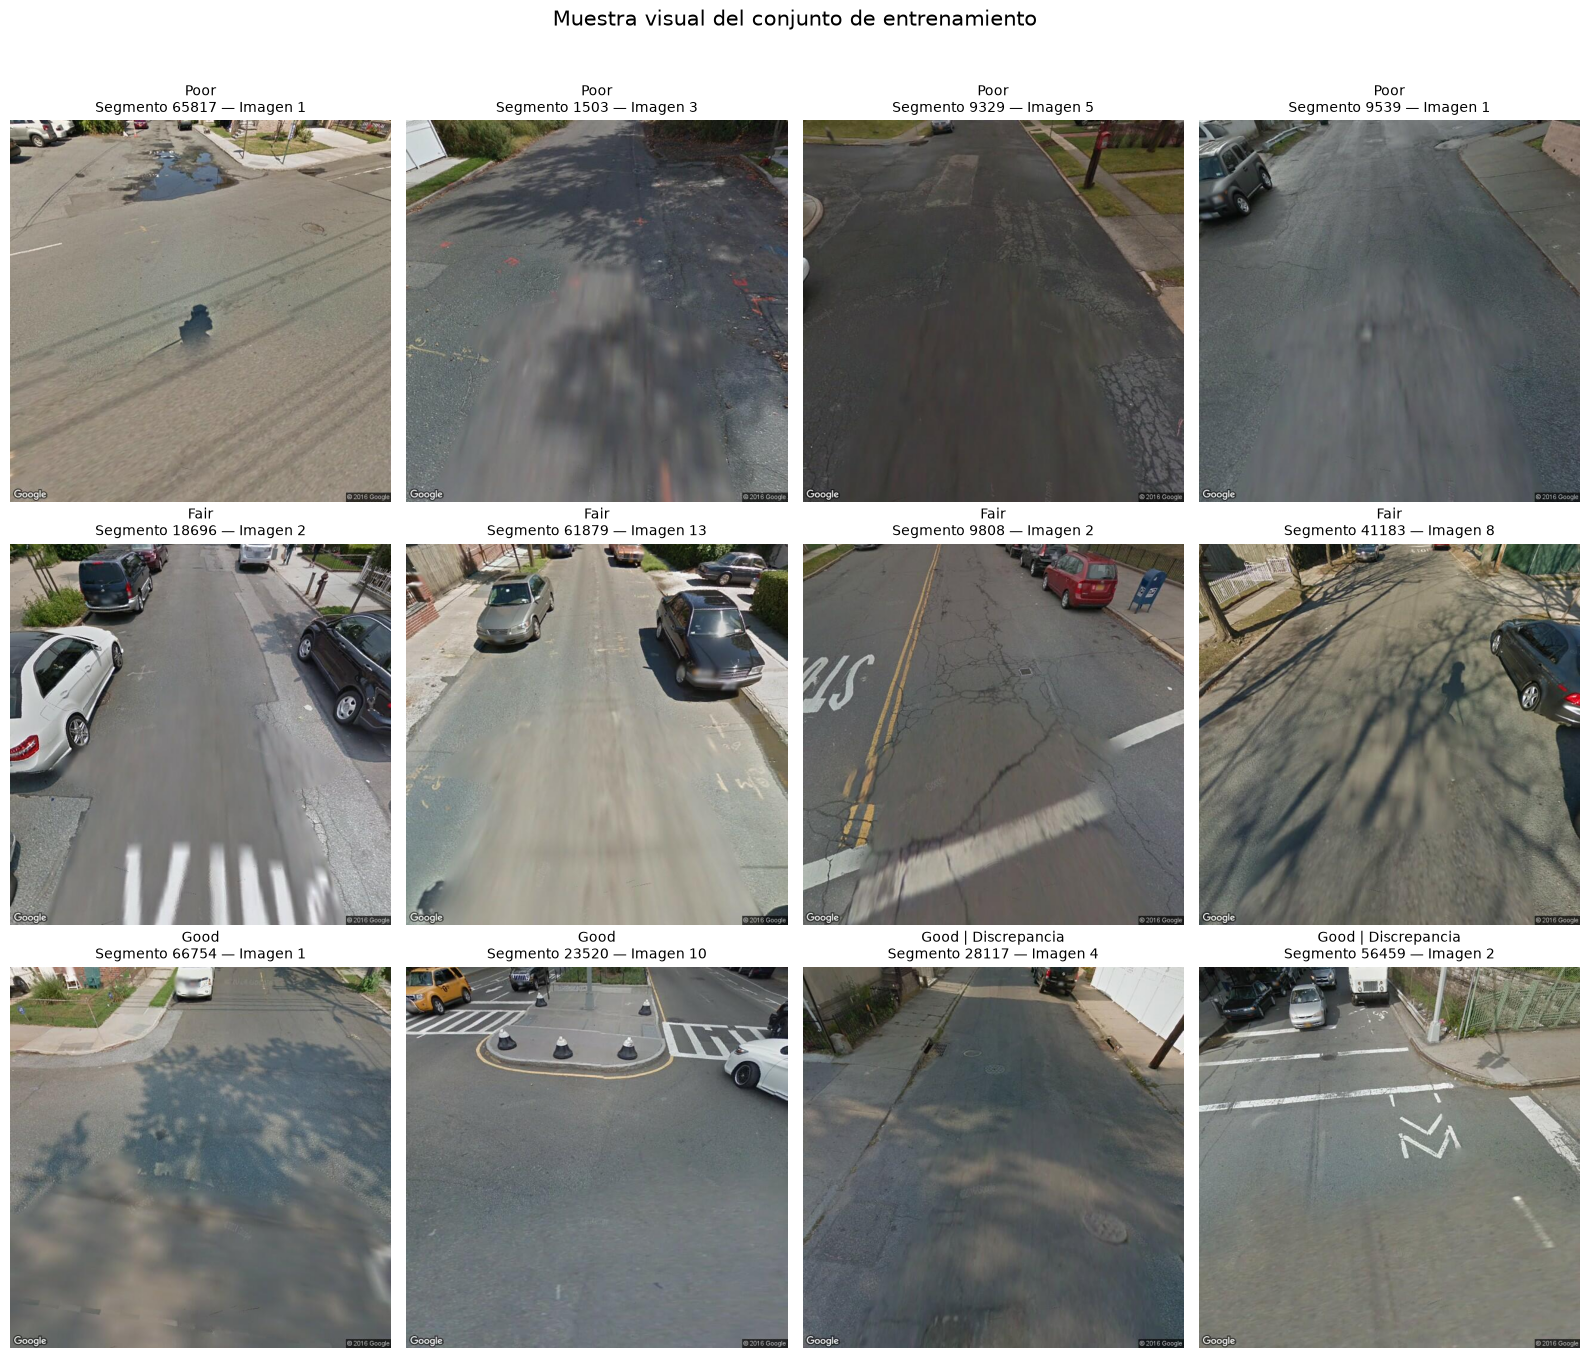

In [16]:
# Seleccionar imágenes de segmentos distintos dentro de cada grupo.
def seleccionar_muestra_visual(tabla, cantidad):
    candidatas = (
        tabla.sort_values(["segmento_id", "numero_imagen"])
        .groupby("segmento_id", group_keys=False)
        .sample(n=1, random_state=SEMILLA)
    )

    return candidatas.sample(
        n=min(cantidad, len(candidatas)),
        random_state=SEMILLA,
    )


muestras = []

for clase_id in NOMBRES_CLASES:
    datos_clase = train_visual.loc[
        train_visual["clase_original"].eq(clase_id)
    ]

    if clase_id == 2:
        # Good: incluir ambos casos para la revisión visual.
        for discrepancia in [False, True]:
            grupo = datos_clase.loc[
                datos_clase["hay_discrepancia"].eq(discrepancia)
            ]
            muestras.append(seleccionar_muestra_visual(grupo, 2))
    else:
        muestras.append(seleccionar_muestra_visual(datos_clase, 4))

muestra_visual = pd.concat(muestras, ignore_index=True)

# Guardar qué imágenes se revisaron para documentar el procedimiento.
muestra_visual.to_csv(
    CARPETA_REPORTES / "muestra_visual_train.csv",
    index=False,
    encoding="utf-8-sig",
)


# Leer la imagen respetando su orientación.
def leer_imagen_rgb(ruta):
    with Image.open(ruta) as img:
        return ImageOps.exif_transpose(img).convert("RGB")


# Mostrar una fila por clase.
fig, ejes = plt.subplots(3, 4, figsize=(16, 14))

for fila, (clase_id, nombre_clase) in enumerate(NOMBRES_CLASES.items()):
    ejemplos = muestra_visual.loc[
        muestra_visual["clase_original"].eq(clase_id)
    ]

    for eje in ejes[fila]:
        eje.axis("off")

    for columna, registro in enumerate(ejemplos.itertuples(index=False)):
        with leer_imagen_rgb(registro.ruta) as imagen:
            ejes[fila, columna].imshow(imagen)

        marca = " | Discrepancia" if registro.hay_discrepancia else ""

        ejes[fila, columna].set_title(
            f"{nombre_clase}{marca}\n"
            f"Segmento {registro.segmento_id} "
            f"— Imagen {registro.numero_imagen}",
            fontsize=10,
        )

fig.suptitle("Muestra visual del conjunto de entrenamiento", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    CARPETA_REPORTES / "muestra_visual_train.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

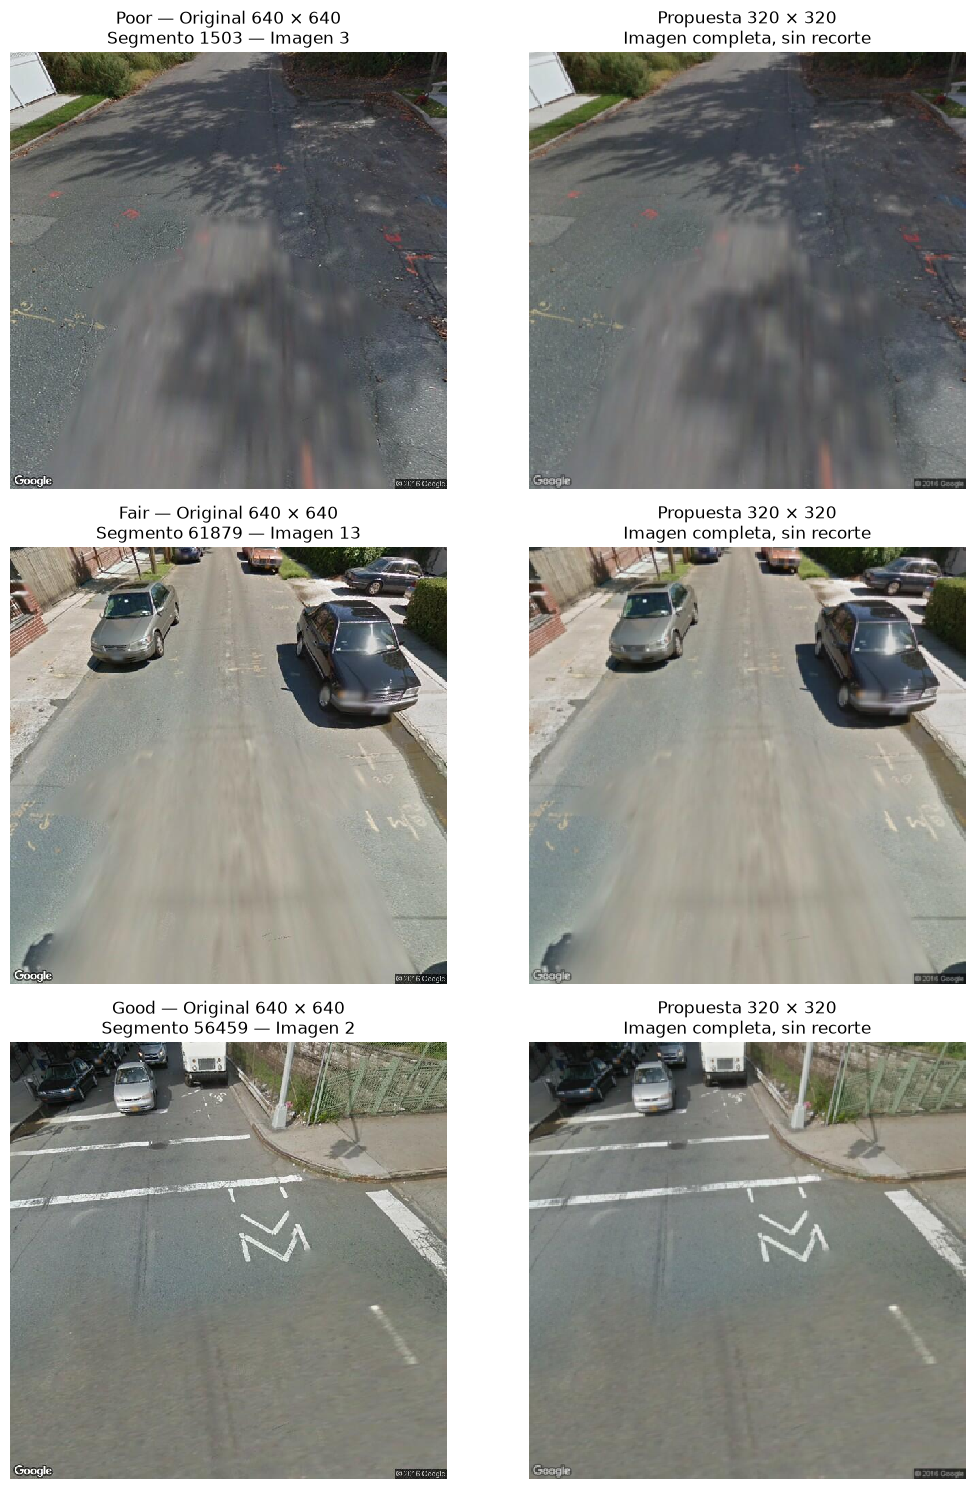

In [17]:
# Propuesta inicial: conservar la imagen completa y reducir su tamaño.
def redimensionar_imagen(imagen_rgb):
    return imagen_rgb.resize(
        TAMANO_ENTRADA,
        resample=Image.Resampling.BILINEAR,
    )


# Comparar una imagen por clase de la muestra ya seleccionada.
muestra_comparacion = (
    muestra_visual.groupby("clase_original", group_keys=False)
    .sample(n=1, random_state=SEMILLA)
    .sort_values("clase_original")
)

fig, ejes = plt.subplots(
    len(muestra_comparacion),
    2,
    figsize=(11, 5 * len(muestra_comparacion)),
    squeeze=False,
)

for fila, registro in enumerate(
    muestra_comparacion.itertuples(index=False)
):
    nombre_clase = NOMBRES_CLASES[registro.clase_original]

    with leer_imagen_rgb(registro.ruta) as original:
        with redimensionar_imagen(original) as preparada:
            ejes[fila, 0].imshow(original, interpolation="nearest")
            ejes[fila, 1].imshow(preparada, interpolation="nearest")

            ejes[fila, 0].set_title(
                f"{nombre_clase} — Original {original.width} × {original.height}\n"
                f"Segmento {registro.segmento_id} "
                f"— Imagen {registro.numero_imagen}"
            )

            ejes[fila, 1].set_title(
                f"Propuesta {preparada.width} × {preparada.height}\n"
                "Imagen completa, sin recorte"
            )

    for eje in ejes[fila]:
        eje.axis("off")

fig.tight_layout()

fig.savefig(
    CARPETA_REPORTES / "comparacion_redimensionamiento.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [18]:
def preparar_entrada_resnet50(imagen_rgb):
    # Recibe una imagen ya redimensionada, con valores entre 0 y 255.
    arreglo = np.array(imagen_rgb, dtype=np.float32)

    # Devuelve la representación numérica que espera ResNet50.
    return preprocess_input(arreglo)

In [19]:
tf.keras.utils.set_random_seed(SEMILLA)

# Cargar los registros existentes, conservando su orden y etiquetas.
registros_carga = {
    nombre: pd.read_csv(
        CARPETA_PARTICIONES / f"imagenes_{nombre}.csv"
    )
    for nombre in NOMBRES_PARTICIONES
}


# 1. Definir aumentos moderados.
def crear_aumento():
    return tf.keras.Sequential(
        [
            tf.keras.layers.RandomFlip(
                mode="horizontal",
                seed=SEMILLA,
            ),
            tf.keras.layers.RandomBrightness(
                factor=0.08,
                value_range=(0, 255),
                seed=SEMILLA + 1,
            ),
            tf.keras.layers.RandomContrast(
                factor=0.08,
                seed=SEMILLA + 2,
            ),
        ],
        name="aumento_pavimento",
    )


aumento_train = crear_aumento()


# 2. Reutilizar la lectura y el redimensionamiento definidos antes.
def cargar_con_pillow(ruta_tensor):
    ruta = ruta_tensor.numpy().decode("utf-8")

    with leer_imagen_rgb(ruta) as original:
        with redimensionar_imagen(original) as preparada:
            return np.array(preparada, dtype=np.float32)


# Conectar la lectura con tf.data.
def cargar_imagen(ruta, etiqueta):
    imagen = tf.py_function(
        func=cargar_con_pillow,
        inp=[ruta],
        Tout=tf.float32,
    )

    # py_function necesita que indiquemos la forma de salida.
    imagen.set_shape(
        (TAMANO_ENTRADA[1], TAMANO_ENTRADA[0], 3)
    )

    return imagen, etiqueta


# 3. Preparar los lotes de entrenamiento.
def preparar_lote_train(imagenes, etiquetas):
    imagenes = aumento_train(imagenes, training=True)
    imagenes = tf.clip_by_value(imagenes, 0.0, 255.0)

    # Aplicar una sola vez y después del aumento.
    imagenes = preprocess_input(imagenes)

    return imagenes, etiquetas


# Validación y prueba: procesamiento fijo, sin aumento.
def preparar_lote_evaluacion(imagenes, etiquetas):
    return preprocess_input(imagenes), etiquetas


# 4. Construir un dataset a partir de su CSV.
def crear_dataset(tabla, entrenamiento=False):
    rutas = tabla["ruta"].astype(str).tolist()
    etiquetas = tabla["clase_original"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (rutas, etiquetas)
    )

    if entrenamiento:
        # Mezclar rutas antes de cargar los píxeles reduce el uso de RAM.
        dataset = dataset.shuffle(
            buffer_size=len(tabla),
            seed=SEMILLA,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        cargar_imagen,
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )

    # Conservar también el último lote, aunque sea más pequeño.
    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    )

    if entrenamiento:
        # Aplicar los aumentos en orden a los lotes.
        dataset = dataset.map(
            preparar_lote_train,
            num_parallel_calls=1,
            deterministic=True,
        )
    else:
        dataset = dataset.map(
            preparar_lote_evaluacion,
            num_parallel_calls=AUTOTUNE,
            deterministic=True,
        )

    # Preparar el siguiente lote mientras se utiliza el actual.
    return dataset.prefetch(1)


# 5. Crear los tres datasets.
ds_train = crear_dataset(
    registros_carga["train"],
    entrenamiento=True,
)

ds_val = crear_dataset(
    registros_carga["val"],
    entrenamiento=False,
)

ds_test = crear_dataset(
    registros_carga["test"],
    entrenamiento=False,
)


# 6. Mostrar la configuración de carga.
resumen_carga = pd.DataFrame(
    [
        {
            "particion": nombre,
            "imagenes": len(registros_carga[nombre]),
            "lotes": (
                len(registros_carga[nombre]) + BATCH_SIZE - 1
            ) // BATCH_SIZE,
            "mezcla_aleatoria": nombre == "train",
            "aumento": nombre == "train",
        }
        for nombre in NOMBRES_PARTICIONES
    ]
).set_index("particion")

display(resumen_carga)

print(f"Tamaño de entrada: {TAMANO_ENTRADA}")
print(f"Tamaño máximo de lote: {BATCH_SIZE}")

,imagenes,lotes,mezcla_aleatoria,aumento
particion,,,,
train,8404,526,True,True
val,1877,118,False,False
test,1731,109,False,False


Tamaño de entrada: (320, 320)
Tamaño máximo de lote: 16


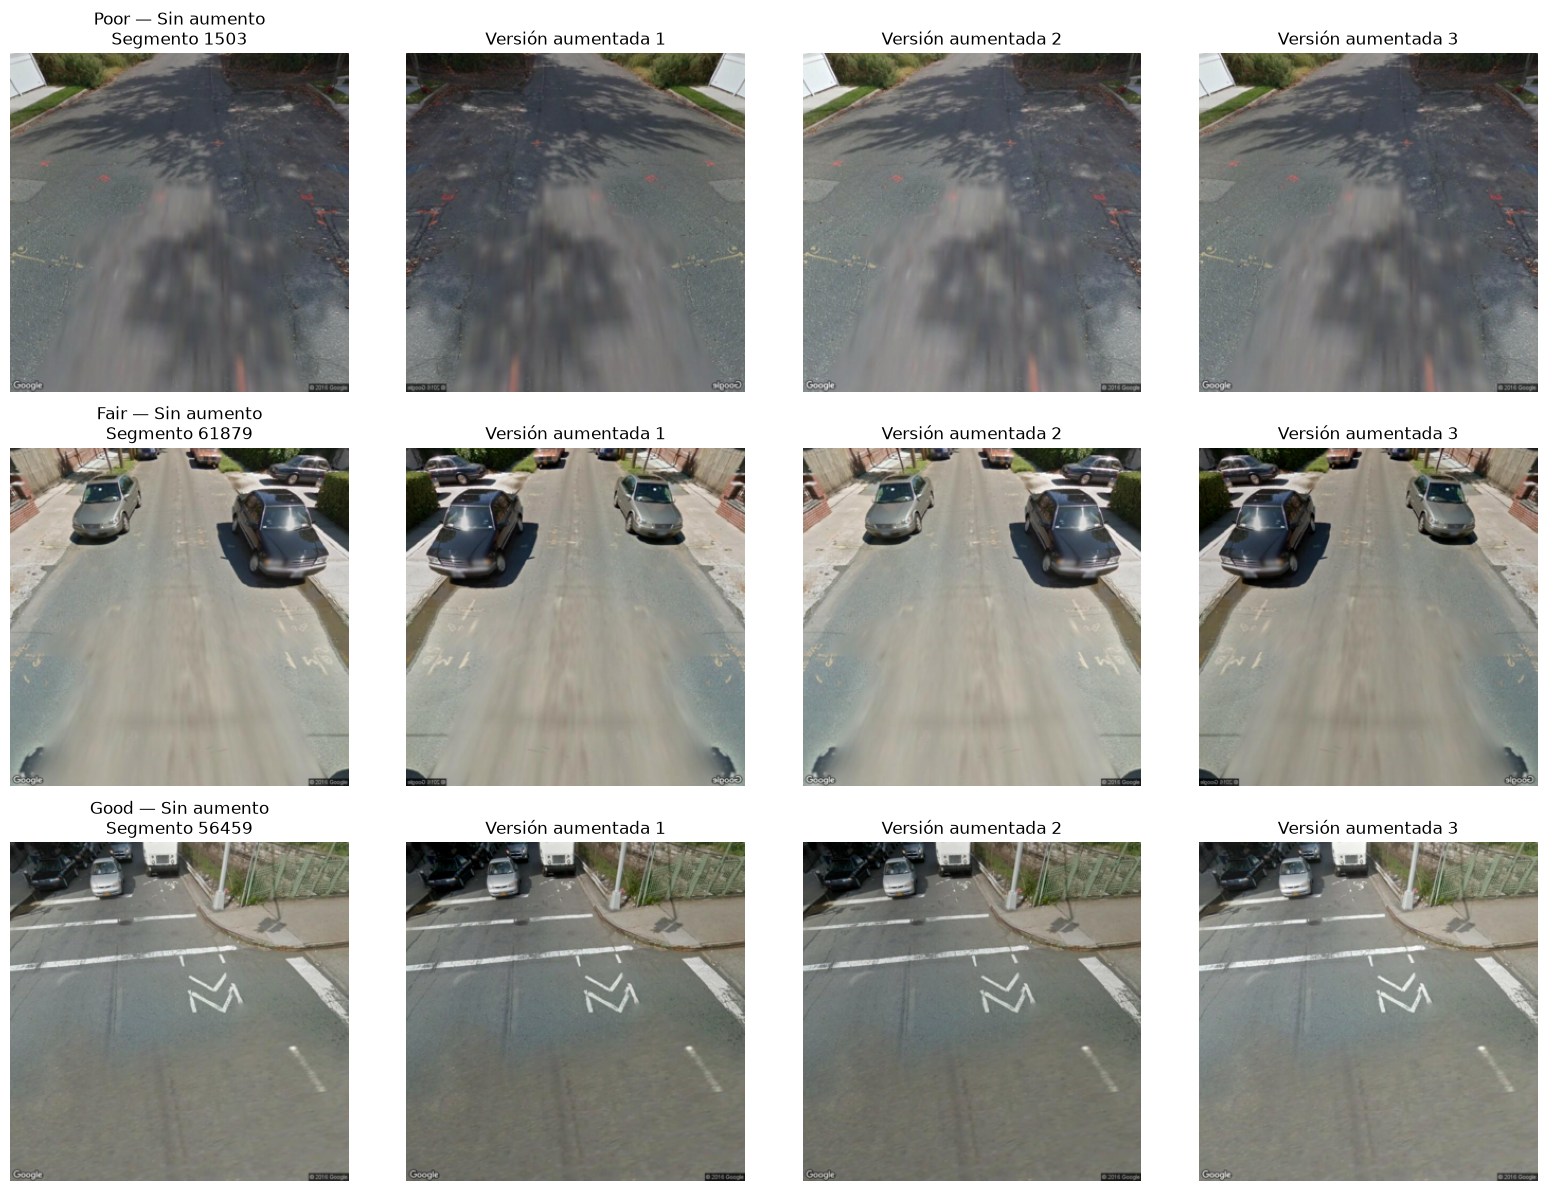

In [20]:
# Reutilizar la muestra visual seleccionada anteriormente.
ejemplos_aumento = (
    muestra_visual.groupby("clase_original", group_keys=False)
    .sample(n=1, random_state=SEMILLA)
    .sort_values("clase_original")
)

aumento_visual = crear_aumento()

fig, ejes = plt.subplots(
    len(ejemplos_aumento),
    4,
    figsize=(16, 12),
    squeeze=False,
)

for fila, registro in enumerate(
    ejemplos_aumento.itertuples(index=False)
):
    with leer_imagen_rgb(registro.ruta) as original:
        with redimensionar_imagen(original) as preparada:
            imagen_rgb = np.array(preparada, dtype=np.float32)

    nombre_clase = NOMBRES_CLASES[registro.clase_original]

    ejes[fila, 0].imshow(imagen_rgb.astype(np.uint8))
    ejes[fila, 0].set_title(
        f"{nombre_clase} — Sin aumento\n"
        f"Segmento {registro.segmento_id}"
    )

    # Añadir la dimensión de lote: (1, alto, ancho, 3).
    lote = tf.convert_to_tensor(imagen_rgb[None, ...])

    for columna in range(1, 4):
        aumentada = aumento_visual(lote, training=True)[0]
        aumentada = tf.clip_by_value(aumentada, 0.0, 255.0)

        ejes[fila, columna].imshow(
            aumentada.numpy().astype(np.uint8)
        )
        ejes[fila, columna].set_title(
            f"Versión aumentada {columna}"
        )

    for eje in ejes[fila]:
        eje.axis("off")

fig.tight_layout()

fig.savefig(
    CARPETA_REPORTES / "ejemplos_aumento_train.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

## CONFIGURACIÓN DE RESNET50

In [22]:
def construir_resnet50():
    tf.keras.utils.set_random_seed(SEMILLA)

    # Cargar la base preentrenada sin su clasificador de ImageNet.
    base = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(
            TAMANO_ENTRADA[1],
            TAMANO_ENTRADA[0],
            3,
        ),
    )

    # Primera fase: entrenar únicamente el clasificador nuevo.
    base.trainable = False

    entradas = tf.keras.Input(
        shape=(TAMANO_ENTRADA[1], TAMANO_ENTRADA[0], 3),
        name="imagen_preprocesada",
    )

    # Las imágenes ya llegan con preprocess_input aplicado.
    # training=False mantiene BatchNormalization en modo inferencia.
    x = base(entradas, training=False)

    # Resumir las características y añadir un clasificador sencillo.
    x = tf.keras.layers.GlobalAveragePooling2D(
        name="promedio_global"
    )(x)

    x = tf.keras.layers.Dropout(
        DROPOUT_CLASIFICADOR,
        seed=SEMILLA,
        name="dropout_clasificador",
    )(x)

    salidas = tf.keras.layers.Dense(
        len(NOMBRES_CLASES),
        activation="softmax",
        name="clasificacion",
    )(x)

    modelo = tf.keras.Model(
        inputs=entradas,
        outputs=salidas,
        name="ResNet50_Pavimento",
    )

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=TASA_APRENDIZAJE_INICIAL
        ),
        # Las etiquetas son enteros: 0, 1 y 2.
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ],
        jit_compile=False,
    )

    return modelo, base


modelo_prueba, base_prueba = construir_resnet50()

modelo_prueba.summary()

print("GPU detectada:", bool(tf.config.list_physical_devices("GPU")))

Model: "ResNet50_Pavimento"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ imagen_preprocesada (InputLayer)     │ (None, 320, 320, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50 (Functional)                │ (None, 10, 10, 2048)        │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ promedio_global                      │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_clasificador (Dropout)       │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ clasificacion (Dense)                │ (None, 3)                   │           6,147 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

GPU detectada: False


In [24]:
# ----------------------------------------------------------------------
# 8.1. PRUEBA CORTA DE ENTRENAMIENTO
# ----------------------------------------------------------------------

# Muestras temporales: los CSV y las particiones no se modifican.
train_corto = (
    registros_carga["train"]
    .groupby("clase_original", group_keys=False)
    .sample(
        n=IMAGENES_TRAIN_POR_CLASE,
        random_state=SEMILLA,
    )
    .reset_index(drop=True)
)

val_corto = (
    registros_carga["val"]
    .groupby("clase_original", group_keys=False)
    .sample(
        n=IMAGENES_VAL_POR_CLASE,
        random_state=SEMILLA,
    )
    .reset_index(drop=True)
)

ds_train_corto = crear_dataset(
    train_corto,
    entrenamiento=True,
)

ds_val_corto = crear_dataset(
    val_corto,
    entrenamiento=False,
)


# Registrar la duración de cada época, incluida la validación.
class TiempoPorEpoca(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.segundos = []

    def on_epoch_begin(self, epoch, logs=None):
        self.inicio = perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.segundos.append(perf_counter() - self.inicio)


tiempos_prueba = TiempoPorEpoca()

print(f"Entrenamiento corto: {len(train_corto):,} imágenes")
print(f"Validación corta: {len(val_corto):,} imágenes")
print(f"Épocas: {EPOCAS_PRUEBA}")

inicio_prueba = perf_counter()

historial_prueba = modelo_prueba.fit(
    ds_train_corto,
    validation_data=ds_val_corto,
    epochs=EPOCAS_PRUEBA,
    callbacks=[
        tiempos_prueba,
        tf.keras.callbacks.TerminateOnNaN(),
    ],
    verbose=1,
)

duracion_prueba = perf_counter() - inicio_prueba

# Guardar métricas y tiempos de esta prueba técnica.
resumen_prueba = pd.DataFrame(historial_prueba.history)

resumen_prueba.insert(
    0,
    "epoca",
    range(1, len(resumen_prueba) + 1),
)

resumen_prueba["segundos"] = tiempos_prueba.segundos

ruta_resumen = CARPETA_REPORTES / "prueba_corta_resnet50.csv"

resumen_prueba.to_csv(
    ruta_resumen,
    index=False,
    encoding="utf-8-sig",
)

print("\n=== RESULTADOS DE LA PRUEBA CORTA ===")
display(resumen_prueba.round(4))

print(f"\nDuración del entrenamiento corto: {duracion_prueba / 60:.2f} minutos")
print(f"Reporte guardado: {ruta_resumen}")

Entrenamiento corto: 384 imágenes
Validación corta: 96 imágenes
Épocas: 2
Epoch 1/2


C:\Users\Diego\Desktop\Tesis_Pavimento\.venv-model\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


24/24 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.3724 - loss: 1.3492 - val_accuracy: 0.3125 - val_loss: 1.2403
Epoch 2/2
24/24 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.3906 - loss: 1.2197 - val_accuracy: 0.4896 - val_loss: 1.0673

=== RESULTADOS DE LA PRUEBA CORTA ===


,epoca,accuracy,loss,val_accuracy,val_loss,segundos
0,1,0.3724,1.3492,0.3125,1.2403,33.1853
1,2,0.3906,1.2197,0.4896,1.0673,27.3941



Duración del entrenamiento corto: 1.01 minutos
Reporte guardado: auditoria_piloto\prueba_corta_resnet50.csv


In [25]:
# ----------------------------------------------------------------------
# 9. ENTRENAMIENTO FORMAL: MÉTRICA F1 MACRO
# ----------------------------------------------------------------------

@tf.keras.utils.register_keras_serializable(package="Pavimento")
class F1Macro(tf.keras.metrics.Metric):
    def __init__(self, num_clases=3, name="f1_macro", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_clases = num_clases

        self.matriz = self.add_weight(
            name="matriz_confusion",
            shape=(num_clases, num_clases),
            initializer="zeros",
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        reales = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        predichas = tf.argmax(y_pred, axis=-1, output_type=tf.int32)

        pesos = None
        if sample_weight is not None:
            pesos = tf.cast(
                tf.reshape(sample_weight, [-1]),
                self.dtype,
            )
            pesos = tf.broadcast_to(pesos, tf.shape(reales))

        matriz_lote = tf.math.confusion_matrix(
            reales,
            predichas,
            num_classes=self.num_clases,
            weights=pesos,
            dtype=self.dtype,
        )

        self.matriz.assign_add(matriz_lote)

    def result(self):
        aciertos = tf.linalg.diag_part(self.matriz)

        reales_por_clase = tf.reduce_sum(self.matriz, axis=1)
        predichas_por_clase = tf.reduce_sum(self.matriz, axis=0)

        f1_por_clase = tf.math.divide_no_nan(
            2.0 * aciertos,
            reales_por_clase + predichas_por_clase,
        )

        return tf.reduce_mean(f1_por_clase)

    def reset_state(self):
        self.matriz.assign(tf.zeros_like(self.matriz))

    def get_config(self):
        config = super().get_config()
        config.update({"num_clases": self.num_clases})
        return config

In [27]:
# ----------------------------------------------------------------------
# 9.1. ENTRENAMIENTO CON LA BASE CONGELADA
# ----------------------------------------------------------------------
# Una carpeta distinta para cada ejecución.
RUN_DIR = (
    Path("resultados_resnet50_DatComple")
    / datetime.now().strftime("fase1_%Y%m%d_%H%M%S")
)
RUN_DIR.mkdir(parents=True, exist_ok=False)

RUTA_MEJOR_MODELO = RUN_DIR / "mejor_modelo.keras"

tf.keras.utils.set_random_seed(SEMILLA)

# Reiniciar el generador de aumentos y recrear los datasets completos.
aumento_train = crear_aumento()

ds_train = crear_dataset(
    registros_carga["train"],
    entrenamiento=True,
)

ds_val = crear_dataset(
    registros_carga["val"],
    entrenamiento=False,
)

# Modelo nuevo: pesos de ImageNet y clasificador recién inicializado.
modelo, base_resnet50 = construir_resnet50()

# Incorporar F1 macro a las métricas.
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=TASA_APRENDIZAJE_INICIAL
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        F1Macro(num_clases=len(NOMBRES_CLASES)),
    ],
    jit_compile=False,
)

tiempos_fase1 = TiempoPorEpoca()

callbacks_fase1 = [
    tf.keras.callbacks.TerminateOnNaN(),

    # Guardar el modelo con el mayor F1 macro de validación.
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(RUTA_MEJOR_MODELO),
        monitor="val_f1_macro",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),

    # Reducir la tasa de aprendizaje tras dos épocas sin mejora.
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_f1_macro",
        mode="max",
        factor=0.5,
        patience=2,
        min_delta=0.0,
        min_lr=1e-6,
        verbose=1,
    ),

    # Detener tras cinco épocas consecutivas sin mejora.
    tf.keras.callbacks.EarlyStopping(
        monitor="val_f1_macro",
        mode="max",
        patience=5,
        min_delta=0.0,
        restore_best_weights=True,
        verbose=1,
    ),

    # Registrar resultados después de cada época.
    tf.keras.callbacks.CSVLogger(
        str(RUN_DIR / "registro_epocas.csv")
    ),

    tiempos_fase1,
]

inicio_fase1 = perf_counter()

historial_fase1 = modelo.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCAS_MAXIMAS_FASE1,
    callbacks=callbacks_fase1,
    shuffle=False,  # La mezcla ya se realiza dentro de ds_train.
    verbose=1,
)

duracion_fase1 = perf_counter() - inicio_fase1

# Guardar el historial con los tiempos.
resultados_fase1 = pd.DataFrame(historial_fase1.history)

resultados_fase1.insert(
    0,
    "epoca",
    range(1, len(resultados_fase1) + 1),
)

resultados_fase1["segundos"] = tiempos_fase1.segundos

resultados_fase1.to_csv(
    RUN_DIR / "historial_fase1.csv",
    index=False,
    encoding="utf-8-sig",
)

# Recuperar exactamente el modelo guardado con mejor validación.
nombre_base = base_resnet50.name
modelo = tf.keras.models.load_model(RUTA_MEJOR_MODELO)
base_resnet50 = modelo.get_layer(nombre_base)

mejor_fila = resultados_fase1.loc[
    resultados_fase1["val_f1_macro"].idxmax()
]

print("\n=== MEJOR ÉPOCA SEGÚN VALIDACIÓN ===")
display(
    mejor_fila[
        ["epoca", "val_loss", "val_accuracy", "val_f1_macro"]
    ].to_frame("valor")
)

print(f"\nDuración total: {duracion_fase1 / 60:.2f} minutos")
print(f"Resultados guardados en: {RUN_DIR.resolve()}")

Epoch 1/15
526/526 ━━━━━━━━━━━━━━━━━━━━ 0s 954ms/step - accuracy: 0.4613 - f1_macro: 0.4609 - loss: 1.1092
Epoch 1: val_f1_macro improved from None to 0.49280, saving model to resultados_resnet50_DatComple\fase1_20261005_151133\mejor_modelo.keras

Epoch 1: finished saving model to resultados_resnet50_DatComple\fase1_20261005_151133\mejor_modelo.keras
526/526 ━━━━━━━━━━━━━━━━━━━━ 620s 1s/step - accuracy: 0.4613 - f1_macro: 0.4609 - loss: 1.1092 - val_accuracy: 0.5274 - val_f1_macro: 0.4928 - val_loss: 0.9528 - learning_rate: 0.0010
Epoch 2/15
526/526 ━━━━━━━━━━━━━━━━━━━━ 0s 924ms/step - accuracy: 0.5189 - f1_macro: 0.5180 - loss: 1.0032
Epoch 2: val_f1_macro improved from 0.49280 to 0.51692, saving model to resultados_resnet50_DatComple\fase1_20261005_151133\mejor_modelo.keras

Epoch 2: finished saving model to resultados_resnet50_DatComple\fase1_20261005_151133\mejor_modelo.keras
526/526 ━━━━━━━━━━━━━━━━━━━━ 593s 1s/step - accuracy: 0.5189 - f1_macro: 0.5180 - loss: 1.0032 - val_accura

,valor
epoca,6.000000
val_loss,0.918967
val_accuracy,0.551945
val_f1_macro,0.554279



Duración total: 108.63 minutos
Resultados guardados en: C:\Users\Diego\Desktop\Tesis_Pavimento\resultados_resnet50_DatComple\fase1_20261005_151133


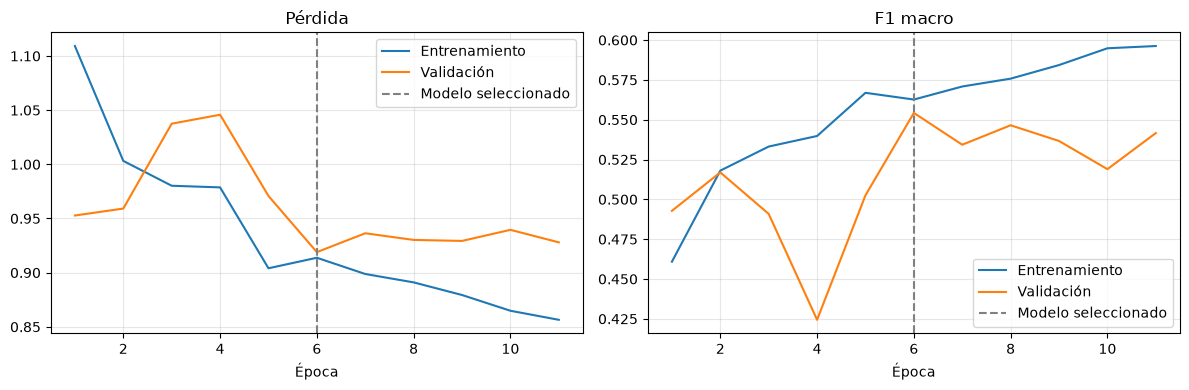

118/118 ━━━━━━━━━━━━━━━━━━━━ 115s 954ms/step

=== RENDIMIENTO EN VALIDACIÓN ===


,precision,recall,f1-score,support
Poor,0.6840,0.6513,0.6673,585.0000
Fair,0.4801,0.3923,0.4318,678.0000
Good,0.5078,0.6336,0.5638,614.0000
accuracy,0.5519,0.5519,0.5519,0.5519
macro avg,0.5573,0.5591,0.5543,1877.0000
weighted avg,0.5527,0.5519,0.5484,1877.0000



=== MATRIZ DE CONFUSIÓN DE VALIDACIÓN ===


Clase predicha,Poor,Fair,Good
Clase original,,,
Poor,381,108,96
Fair,131,266,281
Good,45,180,389


In [29]:
# ----------------------------------------------------------------------
# 9.2. RESULTADOS PARA TOMAR DECISIONES
# ----------------------------------------------------------------------

# Curvas de entrenamiento.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

for eje, metrica, titulo in [
    (ejes[0], "loss", "Pérdida"),
    (ejes[1], "f1_macro", "F1 macro"),
]:
    eje.plot(
        resultados_fase1["epoca"],
        resultados_fase1[metrica],
        label="Entrenamiento",
    )

    eje.plot(
        resultados_fase1["epoca"],
        resultados_fase1[f"val_{metrica}"],
        label="Validación",
    )

    eje.axvline(
        int(mejor_fila["epoca"]),
        color="gray",
        linestyle="--",
        label="Modelo seleccionado",
    )

    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.legend()
    eje.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(RUN_DIR / "curvas_fase1.png", dpi=150)
plt.show()
plt.close(fig)

# ds_val conserva el orden del CSV y no aplica aumentos.
probabilidades_val = modelo.predict(ds_val, verbose=1)
predicciones_val = probabilidades_val.argmax(axis=1)

etiquetas_val = registros_carga["val"]["clase_original"].to_numpy()

ids_clases = list(NOMBRES_CLASES)
nombres = [NOMBRES_CLASES[i] for i in ids_clases]

reporte_val = pd.DataFrame(
    classification_report(
        etiquetas_val,
        predicciones_val,
        labels=ids_clases,
        target_names=nombres,
        output_dict=True,
        zero_division=0,
    )
).T

matriz_val = pd.DataFrame(
    confusion_matrix(
        etiquetas_val,
        predicciones_val,
        labels=ids_clases,
    ),
    index=pd.Index(nombres, name="Clase original"),
    columns=pd.Index(nombres, name="Clase predicha"),
)

print("\n=== RENDIMIENTO EN VALIDACIÓN ===")
display(reporte_val.round(4))

print("\n=== MATRIZ DE CONFUSIÓN DE VALIDACIÓN ===")
display(matriz_val)

reporte_val.to_csv(
    RUN_DIR / "reporte_validacion.csv",
    encoding="utf-8-sig",
)

matriz_val.to_csv(
    RUN_DIR / "matriz_validacion.csv",
    encoding="utf-8-sig",
)

In [31]:
# ----------------------------------------------------------------------
# 10. FASE 2: AJUSTE FINO DEL ÚLTIMO BLOQUE DE RESNET50
# ----------------------------------------------------------------------

# Las variables originales siguen apuntando a la fase 1.
RUTA_MODELO_FASE1 = Path(RUTA_MEJOR_MODELO)

RUN_DIR_FASE2 = (
    RUN_DIR.parent
    / datetime.now().strftime("fase2_%Y%m%d_%H%M%S")
)
RUN_DIR_FASE2.mkdir(parents=True, exist_ok=False)

RUTA_MEJOR_FASE2 = RUN_DIR_FASE2 / "mejor_modelo_fase2.keras"

tf.keras.utils.set_random_seed(SEMILLA)

# Recuperar el mejor modelo anterior, sin reutilizar su optimizador.
modelo_fase2 = tf.keras.models.load_model(
    RUTA_MODELO_FASE1,
    compile=False,
)

base_fase2 = modelo_fase2.get_layer(base_resnet50.name)

# Habilitar la base antes de configurar sus capas individualmente.
base_fase2.trainable = True

for capa in base_fase2.layers:
    pertenece_al_bloque = capa.name.startswith(BLOQUE_A_AJUSTAR)
    es_batch_normalization = isinstance(
        capa,
        tf.keras.layers.BatchNormalization,
    )

    capa.trainable = (
        pertenece_al_bloque and not es_batch_normalization
    )

# Recompilar después de cambiar las capas entrenables.
modelo_fase2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=TASA_APRENDIZAJE_FASE2
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        F1Macro(num_clases=len(NOMBRES_CLASES)),
    ],
    jit_compile=False,
)

# Reiniciar aumentos y mezcla para esta ejecución.
aumento_train = crear_aumento()

ds_train = crear_dataset(
    registros_carga["train"],
    entrenamiento=True,
)

# ds_val mantiene el procesamiento fijo de la fase anterior.

print("Capas de la base cuyos pesos se ajustarán:")
for capa in base_fase2.layers:
    if capa.trainable and capa.trainable_weights:
        print(" -", capa.name)

parametros_entrenables = sum(
    int(np.prod(peso.shape))
    for peso in modelo_fase2.trainable_weights
)

print(f"\nParámetros entrenables totales: {parametros_entrenables:,}")
print("El clasificador final también continúa entrenándose.")
print("Modelo inicial:", RUTA_MODELO_FASE1)
print("Carpeta de resultados:", RUN_DIR_FASE2)

Capas de la base cuyos pesos se ajustarán:
 - conv5_block3_1_conv
 - conv5_block3_2_conv
 - conv5_block3_3_conv

Parámetros entrenables totales: 4,465,667
El clasificador final también continúa entrenándose.
Modelo inicial: resultados_resnet50_DatComple\fase1_20261005_151133\mejor_modelo.keras
Carpeta de resultados: resultados_resnet50_DatComple\fase2_20261005_175124


In [32]:
# ----------------------------------------------------------------------
# 10.1. ENTRENAMIENTO DEL AJUSTE FINO
# ----------------------------------------------------------------------

tiempos_fase2 = TiempoPorEpoca()

callbacks_fase2 = [
    tf.keras.callbacks.TerminateOnNaN(),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(RUTA_MEJOR_FASE2),
        monitor="val_f1_macro",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_f1_macro",
        mode="max",
        factor=0.5,
        patience=2,
        min_delta=0.0,
        min_lr=1e-7,
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_f1_macro",
        mode="max",
        patience=4,
        min_delta=0.0,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.CSVLogger(
        str(RUN_DIR_FASE2 / "registro_epocas.csv")
    ),

    tiempos_fase2,
]

inicio_fase2 = perf_counter()

historial_fase2 = modelo_fase2.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCAS_MAXIMAS_FASE2,
    callbacks=callbacks_fase2,
    shuffle=False,
    verbose=1,
)

duracion_fase2 = perf_counter() - inicio_fase2

resultados_fase2 = pd.DataFrame(historial_fase2.history)

resultados_fase2.insert(
    0,
    "epoca",
    range(1, len(resultados_fase2) + 1),
)

resultados_fase2["segundos"] = tiempos_fase2.segundos

resultados_fase2.to_csv(
    RUN_DIR_FASE2 / "historial_fase2.csv",
    index=False,
    encoding="utf-8-sig",
)

# Cargar exactamente el mejor checkpoint de esta fase.
modelo_fase2 = tf.keras.models.load_model(RUTA_MEJOR_FASE2)

mejor_fase2 = resultados_fase2.loc[
    resultados_fase2["val_f1_macro"].idxmax()
].copy()

print("\n=== MEJOR ÉPOCA DE LA FASE 2 ===")
display(
    mejor_fase2[
        ["epoca", "val_loss", "val_accuracy", "val_f1_macro"]
    ].to_frame("valor")
)

print(f"\nDuración de la fase 2: {duracion_fase2 / 60:.2f} minutos")

Epoch 1/10
526/526 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5985 - f1_macro: 0.5975 - loss: 0.8502
Epoch 1: val_f1_macro improved from None to 0.54457, saving model to resultados_resnet50_DatComple\fase2_20261005_175124\mejor_modelo_fase2.keras

Epoch 1: finished saving model to resultados_resnet50_DatComple\fase2_20261005_175124\mejor_modelo_fase2.keras
526/526 ━━━━━━━━━━━━━━━━━━━━ 654s 1s/step - accuracy: 0.5985 - f1_macro: 0.5975 - loss: 0.8502 - val_accuracy: 0.5429 - val_f1_macro: 0.5446 - val_loss: 0.9227 - learning_rate: 1.0000e-05
Epoch 2/10
526/526 ━━━━━━━━━━━━━━━━━━━━ 0s 979ms/step - accuracy: 0.6266 - f1_macro: 0.6257 - loss: 0.8135
Epoch 2: val_f1_macro improved from 0.54457 to 0.54608, saving model to resultados_resnet50_DatComple\fase2_20261005_175124\mejor_modelo_fase2.keras

Epoch 2: finished saving model to resultados_resnet50_DatComple\fase2_20261005_175124\mejor_modelo_fase2.keras
526/526 ━━━━━━━━━━━━━━━━━━━━ 619s 1s/step - accuracy: 0.6266 - f1_macro: 0.6257 - 

,valor
epoca,2.000000
val_loss,0.925226
val_accuracy,0.540757
val_f1_macro,0.546075



Duración de la fase 2: 66.32 minutos


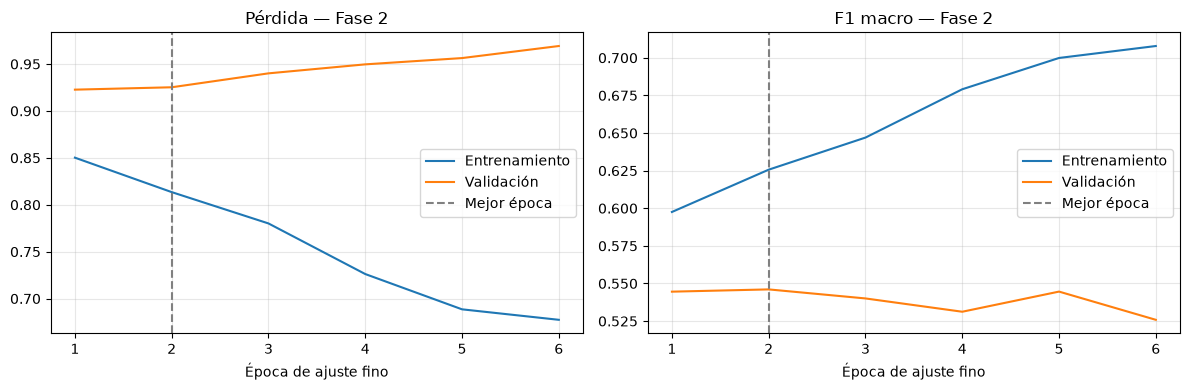

118/118 ━━━━━━━━━━━━━━━━━━━━ 118s 985ms/step

=== RENDIMIENTO EN VALIDACIÓN — FASE 2 ===


,precision,recall,f1-score,support
Poor,0.6690,0.6427,0.6556,585.0000
Fair,0.4599,0.4985,0.4784,678.0000
Good,0.5190,0.4902,0.5042,614.0000
accuracy,0.5408,0.5408,0.5408,0.5408
macro avg,0.5493,0.5438,0.5461,1877.0000
weighted avg,0.5444,0.5408,0.5421,1877.0000



=== MATRIZ DE CONFUSIÓN — FASE 2 ===


Clase predicha,Poor,Fair,Good
Clase original,,,
Poor,376,136,73
Fair,134,338,206
Good,52,261,301


In [33]:
# ----------------------------------------------------------------------
# 10.2. CURVAS Y RENDIMIENTO POR CLASE DE LA FASE 2
# ----------------------------------------------------------------------

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

for eje, metrica, titulo in [
    (ejes[0], "loss", "Pérdida — Fase 2"),
    (ejes[1], "f1_macro", "F1 macro — Fase 2"),
]:
    eje.plot(
        resultados_fase2["epoca"],
        resultados_fase2[metrica],
        label="Entrenamiento",
    )
    eje.plot(
        resultados_fase2["epoca"],
        resultados_fase2[f"val_{metrica}"],
        label="Validación",
    )
    eje.axvline(
        int(mejor_fase2["epoca"]),
        color="gray",
        linestyle="--",
        label="Mejor época",
    )

    eje.set_title(titulo)
    eje.set_xlabel("Época de ajuste fino")
    eje.legend()
    eje.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(RUN_DIR_FASE2 / "curvas_fase2.png", dpi=150)
plt.show()
plt.close(fig)

# Evaluar el mejor modelo de la fase 2 sobre validación.
probabilidades_fase2 = modelo_fase2.predict(ds_val, verbose=1)
predicciones_fase2 = probabilidades_fase2.argmax(axis=1)

etiquetas_val = registros_carga["val"]["clase_original"].to_numpy()
ids_clases = list(NOMBRES_CLASES)
nombres = [NOMBRES_CLASES[i] for i in ids_clases]

reporte_val_fase2 = pd.DataFrame(
    classification_report(
        etiquetas_val,
        predicciones_fase2,
        labels=ids_clases,
        target_names=nombres,
        output_dict=True,
        zero_division=0,
    )
).T

matriz_val_fase2 = pd.DataFrame(
    confusion_matrix(
        etiquetas_val,
        predicciones_fase2,
        labels=ids_clases,
    ),
    index=pd.Index(nombres, name="Clase original"),
    columns=pd.Index(nombres, name="Clase predicha"),
)

print("\n=== RENDIMIENTO EN VALIDACIÓN — FASE 2 ===")
display(reporte_val_fase2.round(4))

print("\n=== MATRIZ DE CONFUSIÓN — FASE 2 ===")
display(matriz_val_fase2)

reporte_val_fase2.to_csv(
    RUN_DIR_FASE2 / "reporte_validacion.csv",
    encoding="utf-8-sig",
)

matriz_val_fase2.to_csv(
    RUN_DIR_FASE2 / "matriz_validacion.csv",
    encoding="utf-8-sig",
)

In [34]:
# ----------------------------------------------------------------------
# 10.3. COMPARACIÓN Y SELECCIÓN ENTRE AMBAS FASES
# ----------------------------------------------------------------------
from shutil import copy2

mejor_fase1 = resultados_fase1.loc[
    resultados_fase1["val_f1_macro"].idxmax()
].copy()

comparacion_fases = pd.DataFrame(
    [
        {
            "fase": nombre,
            "mejor_epoca": int(resultado["epoca"]),
            "val_loss": float(resultado["val_loss"]),
            "val_accuracy": float(resultado["val_accuracy"]),
            "val_f1_macro": float(resultado["val_f1_macro"]),
        }
        for nombre, resultado in [
            ("Fase 1", mejor_fase1),
            ("Fase 2", mejor_fase2),
        ]
    ]
).set_index("fase")

if mejor_fase2["val_f1_macro"] > mejor_fase1["val_f1_macro"]:
    fase_seleccionada = "Fase 2"
    ruta_origen = RUTA_MEJOR_FASE2
else:
    fase_seleccionada = "Fase 1"
    ruta_origen = RUTA_MODELO_FASE1

comparacion_fases["seleccionada"] = (
    comparacion_fases.index == fase_seleccionada
)

comparacion_fases.to_csv(
    RUN_DIR_FASE2 / "comparacion_fases.csv",
    encoding="utf-8-sig",
)

# Copiar el checkpoint seleccionado sin sobrescribir los originales.
RUTA_MODELO_SELECCIONADO = (
    RUN_DIR_FASE2 / "modelo_seleccionado.keras"
)
copy2(ruta_origen, RUTA_MODELO_SELECCIONADO)

# Dejar el mejor modelo disponible para las siguientes secciones.
modelo = tf.keras.models.load_model(RUTA_MODELO_SELECCIONADO)
base_resnet50 = modelo.get_layer(base_fase2.name)

diferencia_f1 = (
    mejor_fase2["val_f1_macro"] - mejor_fase1["val_f1_macro"]
)

print("\n=== COMPARACIÓN ENTRE FASES ===")
display(comparacion_fases.round(4))

print(
    f"\nCambio de F1 macro: "
    f"{diferencia_f1 * 100:+.2f} puntos porcentuales"
)
print("Fase seleccionada:", fase_seleccionada)
print("Modelo guardado:", RUTA_MODELO_SELECCIONADO.resolve())


=== COMPARACIÓN ENTRE FASES ===


,mejor_epoca,val_loss,val_accuracy,val_f1_macro,seleccionada
fase,,,,,
Fase 1,6,0.9190,0.5519,0.5543,True
Fase 2,2,0.9252,0.5408,0.5461,False



Cambio de F1 macro: -0.82 puntos porcentuales
Fase seleccionada: Fase 1
Modelo guardado: C:\Users\Diego\Desktop\Tesis_Pavimento\resultados_resnet50_DatComple\fase2_20261005_175124\modelo_seleccionado.keras
